In [1]:
import subprocess
import torch

print("torch      :", torch.__version__)
print("built for  :", "CUDA " + str(torch.version.cuda))
print("GPU visible:", torch.cuda.is_available())
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print("name       :", p.name)
    print("capability : sm_%d%d" % (p.major, p.minor))
    print("memory     : %.1f GiB" % (p.total_memory / 2**30))


torch      : 2.2.1+cu121
built for  : CUDA 12.1
GPU visible: True
name       : NVIDIA GeForce GTX 1080 Ti
capability : sm_61
memory     : 10.9 GiB


In [2]:
import torch
from torch import nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt
from pathlib import Path
import kagglehub
from ignite.engine import Engine
from ignite.metrics import FID, InceptionScore

# Hyperparameters
IMG_SIZE   = 128
LATENT_DIM = 128
EPOCHS     = 100
BATCH_SIZE = 64
LR         = 1e-3
SEED       = 0

torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

DATA_DIR = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
# DATA_DIR = "/home/z3qi/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2"
OUT_DIR       = "vae_xray_outputs"
print("DATA_DIR =", DATA_DIR)

DATA_DIR = /home/z3qi/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2


In [3]:
# Data
root = Path(DATA_DIR) / "chest_xray"
tf = transforms.Compose([transforms.Grayscale(),
                         transforms.Resize((IMG_SIZE, IMG_SIZE)),
                         transforms.ToTensor()]) # pixels in [0, 1]

def load(split):  # all images -> one tensor [N,1,H,W]
    ds = datasets.ImageFolder(root / split, tf)
    return torch.stack([img for img, _ in ds]).to(device)

train_x, test_x = load("train"), load("test")
print(train_x.shape, test_x.shape)



torch.Size([5216, 1, 128, 128]) torch.Size([624, 1, 128, 128])


In [4]:
# Model
def down(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 4, 2, 1), nn.BatchNorm2d(cout), nn.LeakyReLU(0.2))

def up(cin, cout):
    return nn.Sequential(nn.ConvTranspose2d(cin, cout, 4, 2, 1), nn.BatchNorm2d(cout), nn.LeakyReLU(0.2))

class ConvVAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        # Encoder: 1x128x128 -> 256x4x4 -> (mu, logvar)
        self.encoder = nn.Sequential(down(1, 32), down(32, 64), down(64, 128),
                                     down(128, 256), down(256, 256), nn.Flatten())
        self.fc_mu = nn.Linear(256 * 4 * 4, latent_dim)
        self.fc_logvar = nn.Linear(256 * 4 * 4, latent_dim)
        # Decoder: z -> 256x4x4 -> 1x128x128 logits
        self.fc_dec = nn.Linear(latent_dim, 256 * 4 * 4)
        self.decoder = nn.Sequential(up(256, 256), up(256, 128), up(128, 64), up(64, 32),
                                     nn.ConvTranspose2d(32, 1, 4, 2, 1))

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + torch.randn_like(std) * std

    def decode(self, z):
        return self.decoder(self.fc_dec(z).view(-1, 256, 4, 4))

    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(self.reparameterize(mu, logvar)), mu, logvar

# Loss: negative ELBO
def vae_loss(logits, x, mu, logvar):
    recon = F.binary_cross_entropy_with_logits(logits, x, reduction="sum")
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon + kl



Epoch   1 | train loss  10230.1 | test loss   9785.4
Epoch   2 | train loss   9694.9 | test loss   9654.4
Epoch   3 | train loss   9623.2 | test loss   9600.5
Epoch   4 | train loss   9577.7 | test loss   9597.5
Epoch   5 | train loss   9560.2 | test loss   9562.1
Epoch   6 | train loss   9539.7 | test loss   9523.2
Epoch   7 | train loss   9528.9 | test loss   9514.5
Epoch   8 | train loss   9513.8 | test loss   9518.3
Epoch   9 | train loss   9509.9 | test loss   9518.4
Epoch  10 | train loss   9500.7 | test loss   9495.0
Epoch  11 | train loss   9498.9 | test loss   9490.1
Epoch  12 | train loss   9492.8 | test loss   9485.7
Epoch  13 | train loss   9486.0 | test loss   9477.4
Epoch  14 | train loss   9483.0 | test loss   9482.5
Epoch  15 | train loss   9479.4 | test loss   9525.9
Epoch  16 | train loss   9481.2 | test loss   9485.7
Epoch  17 | train loss   9474.6 | test loss   9473.0
Epoch  18 | train loss   9475.8 | test loss   9481.9
Epoch  19 | train loss   9472.8 | test loss   

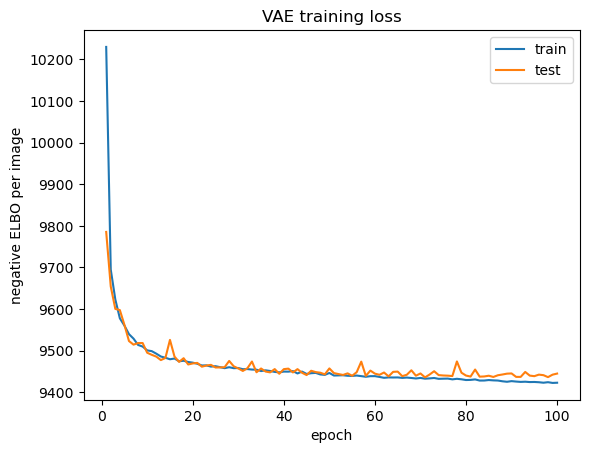

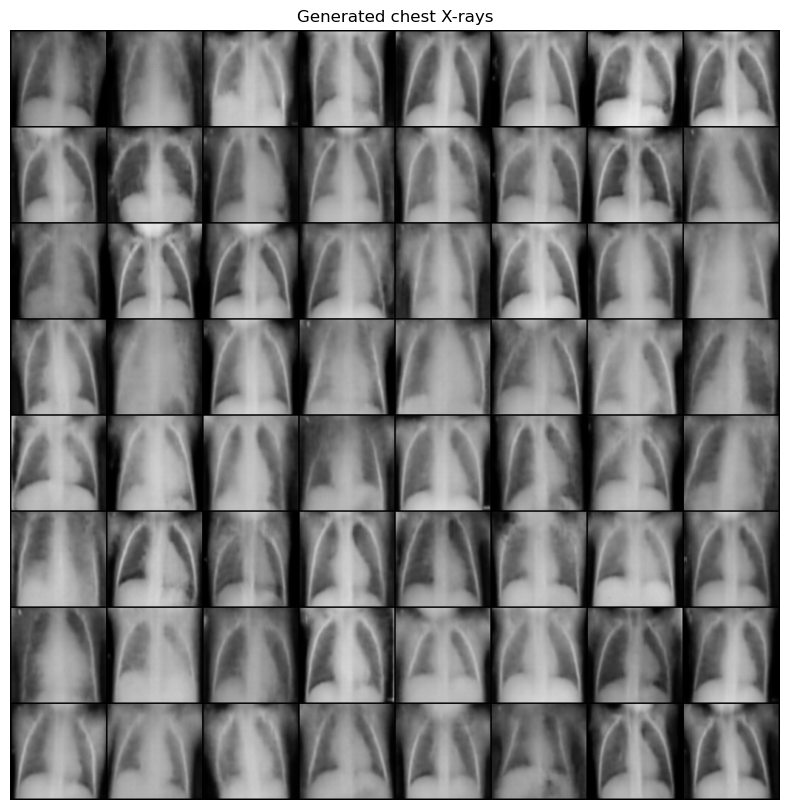

In [5]:
# Train
model = ConvVAE().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
train_hist, test_hist = [], []

for epoch in range(1, EPOCHS + 1):
    model.train()
    total = 0.0
    for x in train_x[torch.randperm(len(train_x), device=device)].split(BATCH_SIZE):
        logits, mu, logvar = model(x)
        loss = vae_loss(logits, x, mu, logvar)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item()

    model.eval()
    with torch.no_grad():
        test_total = 0.0
        for x in test_x.split(128):
            logits, mu, logvar = model(x)
            test_total += vae_loss(logits, x, mu, logvar).item()

    train_hist.append(total / len(train_x))
    test_hist.append(test_total / len(test_x))
    print(f"Epoch {epoch:3d} | train loss {train_hist[-1]:8.1f} | test loss {test_hist[-1]:8.1f}")

# Loss curve
plt.plot(range(1, EPOCHS + 1), train_hist, label="train")
plt.plot(range(1, EPOCHS + 1), test_hist, label="test")
plt.xlabel("epoch"); plt.ylabel("negative ELBO per image"); plt.legend()
plt.title("VAE training loss"); plt.savefig("loss_curve.pdf", bbox_inches="tight"); plt.show()

# Generated samples
with torch.no_grad():
    samples = torch.sigmoid(model.decode(torch.randn(64, LATENT_DIM, device=device)))
plt.figure(figsize=(10, 10))
plt.imshow(make_grid(samples.cpu(), nrow=8).permute(1, 2, 0))
plt.axis("off"); plt.title("Generated chest X-rays"); plt.savefig("samples.png", dpi=200, bbox_inches="tight"); plt.show()



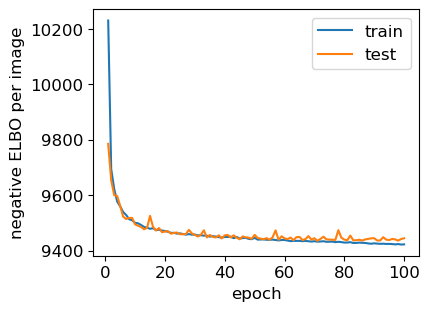

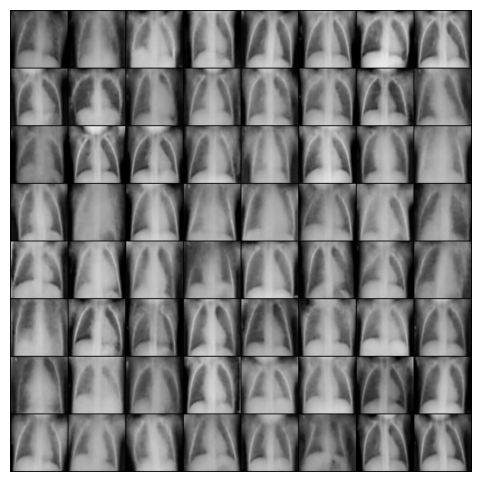

In [10]:
plt.rcParams.update({"font.size": 12})
plt.figure(figsize=(4.2, 3.2))
plt.plot(range(1, EPOCHS + 1), train_hist, label="train")
plt.plot(range(1, EPOCHS + 1), test_hist, label="test")
plt.xlabel("epoch"); plt.ylabel("negative ELBO per image"); plt.legend()
plt.savefig("loss_curve.pdf", bbox_inches="tight"); plt.show()

plt.figure(figsize=(6, 6))
plt.imshow(make_grid(samples.cpu(), nrow=8).permute(1, 2, 0))
plt.axis("off")
plt.savefig("samples.png", dpi=200, bbox_inches="tight", pad_inches=0); plt.show()

In [6]:
torch.save(model.state_dict(), "vae_xray.pt")

In [7]:
from ignite.engine import Engine
from ignite.metrics import FID, InceptionScore

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def prep(x): # [B,1,128,128] in [0,1] -> [B,3,299,299], ImageNet-normalized
    x = F.interpolate(x.repeat(1, 3, 1, 1), size=(299, 299), mode="bilinear", align_corners=False)
    return (x - MEAN) / STD

def ignite_scores(make_fake):
    def evaluation_step(engine, real):
        with torch.no_grad():
            fake = make_fake(real)
            return prep(fake), prep(real) # (generated, real)

    evaluator = Engine(evaluation_step)
    FID(device=torch.device(device)).attach(evaluator, "fid")
    InceptionScore(device=torch.device(device), output_transform=lambda x: x[0]).attach(evaluator, "is")
    evaluator.run(test_x.split(64), max_epochs=1)
    return evaluator.state.metrics["fid"], evaluator.state.metrics["is"]

model.eval()
ignite_cases = {
    "VAE samples":   lambda r: torch.sigmoid(model.decode(torch.randn(len(r), LATENT_DIM, device=device))),
    "Real (train)":  lambda r: train_x[torch.randint(len(train_x), (len(r),), device=device)],
    "Uniform noise": lambda r: torch.rand_like(r),
    "Flat grey":     lambda r: torch.full_like(r, 0.5),
}
print("PyTorch-Ignite")
for name, fn in ignite_cases.items():
    fid, is_ = ignite_scores(fn)
    print(f"{name:14s} FID {fid:8.3f}   IS {is_:.3f}")

PyTorch-Ignite
VAE samples    FID    0.205   IS 1.937
Real (train)   FID    0.012   IS 2.333
Uniform noise  FID    0.165   IS 1.123
Flat grey      FID    0.135   IS 1.000


In [9]:
model = ConvVAE().to(device)
model.load_state_dict(torch.load("vae_xray.pt"))
model.eval()

from torchmetrics.image.fid import FrechetInceptionDistance
from torchmetrics.image.inception import InceptionScore as TMInceptionScore

def tm_scores(make_fake):
    fid = FrechetInceptionDistance(feature=2048, normalize=True).to(device)
    isc = TMInceptionScore(normalize=True).to(device)
    with torch.no_grad():
        for real in test_x.split(64):
            fake = make_fake(real)
            fid.update(real.repeat(1, 3, 1, 1), real=True)
            fid.update(fake.repeat(1, 3, 1, 1), real=False)
            isc.update(fake.repeat(1, 3, 1, 1))
    m, s = isc.compute()
    return fid.compute().item(), m.item(), s.item()

model.eval()
cases = {
    "VAE samples":   lambda r: torch.sigmoid(model.decode(torch.randn(len(r), LATENT_DIM, device=device))),
    "Real (train)":  lambda r: train_x[torch.randint(len(train_x), (len(r),), device=device)],
    "Uniform noise": lambda r: torch.rand_like(r),
    "Flat grey":     lambda r: torch.full_like(r, 0.5),
}
for name, fn in cases.items():
    f, m, s = tm_scores(fn)
    print(f"{name:14s} FID {f:8.2f}   IS {m:.3f} ± {s:.3f}")

/home/z3qi/.local/lib/python3.11/site-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `InceptionScore` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


VAE samples    FID   270.09   IS 2.100 ± 0.127
Real (train)   FID    27.10   IS 2.219 ± 0.109
Uniform noise  FID   485.52   IS 1.191 ± 0.028
Flat grey      FID   475.83   IS 1.000 ± 0.000
